<a href="https://colab.research.google.com/github/sophiajli29-web/swot/blob/master/Track2_Civil_Comments_COSC_74_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

ds = load_dataset("google/civil_comments")   # ~415 MB download the first time
train = ds["train"].to_pandas()
test = ds["test"].to_pandas()
val = ds["validation"].to_pandas()

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (2 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

In [ ]:
# Basics and data quality
print("Train:", train.shape, "| Test:", test.shape)
print("Columns:", train.columns.tolist())
print("Missing values (train):", train.isna().sum().sum())
print("Duplicate texts (train):", train["text"].duplicated().sum())
print("Texts appearing in both train and test:",
      len(set(train["text"]) & set(test["text"])))
print("Texts appearing in both train and validation:",
      len(set(train["text"]) & set(val["text"])))

Train: (1804874, 8) | Test: (97320, 8)
Columns: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']
Missing values (train): 0
Duplicate texts (train): 24051
Texts appearing in both train and test: 1217
Texts appearing in both train and validation: 1170


Toxic rate train: 0.08 | test: 0.0799
Borderline (0.3-0.7): 220638
count    1.804874e+06
mean     1.030173e-01
std      1.971960e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.666667e-01
max      1.000000e+00
Name: toxicity, dtype: float64


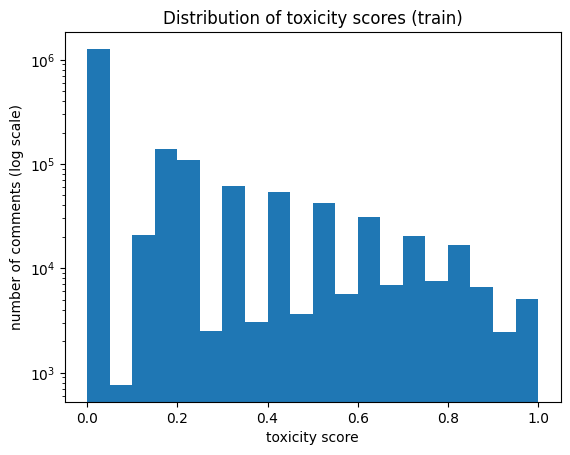

In [ ]:
# Label distribution
for df in (train, test):
    df["toxic"] = (df["toxicity"] >= 0.5).astype(int)
print("Toxic rate train:", round(train["toxic"].mean(), 4),
      "| test:", round(test["toxic"].mean(), 4))
print("Borderline (0.3-0.7):",
      ((train["toxicity"] >= 0.3) & (train["toxicity"] <= 0.7)).sum())
print(train["toxicity"].describe())

plt.hist(train["toxicity"], bins=20)
plt.yscale("log")
plt.xlabel("toxicity score"); plt.ylabel("number of comments (log scale)")
plt.title("Distribution of toxicity scores (train)")
plt.show()

In [ ]:
# Comment length
print("\nWords per comment:")
print(train["text"].str.split().str.len().describe())


Words per comment:
count    1.804874e+06
mean     5.127690e+01
std      4.617811e+01
min      1.000000e+00
25%      1.600000e+01
50%      3.500000e+01
75%      7.200000e+01
max      3.170000e+02
Name: text, dtype: float64


In [ ]:
# Group sizes using identity terms (this takes a minute or two)
terms = {
    "muslim": r"\b(?:muslims?|islam|islamic)\b",
    "black": r"\b(?:blacks|black (?:people|persons?|men|man|women|woman|folks?|community|communities|americans?|kids?|children|students?|youth|males?|females?|citizens|voters))\b",
    "white": r"\b(?:(?<!egg )whites|white (?:people|persons?|men|man|women|woman|folks?|community|communities|americans?|kids?|children|students?|youth|males?|females?|citizens|voters))\b",
    "women": r"\b(?:women|woman|females?)\b",
    "immigrant": r"\b(?:immigrants?|immigration|refugees?|migrants?|undocumented|illegal aliens?|illegals)\b",
    "job": r"\b(?:jobs?|employment|employers?|careers?|hiring)\b",


}

def group_table(df):
    rows = []
    for g, pat in terms.items():
        m = df["text"].str.contains(pat, case=False, regex=True)
        rows.append({"group": g,
                     "n_comments": int(m.sum()),
                     "n_toxic": int(df.loc[m, "toxic"].sum()),
                     "toxic_rate": round(df.loc[m, "toxic"].mean(), 3)})
    return pd.DataFrame(rows)

print("\nTRAIN groups"); print(group_table(train).to_string(index=False))
print("\nTEST groups");  print(group_table(test).to_string(index=False))



TRAIN groups


In [ ]:
# Representative examples
print("\nExamples:")
for lab, name in [(0, "non-toxic"), (1, "toxic")]:
    for t in train[train["toxic"] == lab]["text"].sample(2, random_state=0):
        print(f"[{name}]", t[:200])

for g in ["muslim", "immigrant"]:
    m = train["text"].str.contains(terms[g], case=False, regex=True) & (train["toxic"] == 0)
    print(f"[non-toxic, mentions {g}]", train[m]["text"].iloc[0][:200])

# Group sizes in train
print("\nGroup counts (train):")
for g, pat in terms.items():
    m = train["text"].str.contains(pat, case=False, regex=True)
    print(f"{g:10s} n = {m.sum():7d} | toxic = {int(train.loc[m, 'toxic'].sum()):6d} | toxic rate = {train.loc[m, 'toxic'].mean():.4f}")

# Ambiguity check: bare word vs. phrase pattern for black/white
for g in ["black", "white"]:
    bare = train["text"].str.contains(rf"\b{g}\b", case=False, regex=True)
    phrase = train["text"].str.contains(terms[g], case=False, regex=True)
    print(f"\n'{g}' bare word: {bare.sum()} | identity-phrase pattern: {phrase.sum()} "
          f"| bare-only (likely color/other): {(bare & ~phrase).sum()}")

    print(f"[{g}] bare-word matches NOT caught by the phrase pattern:")
    for t in train[bare & ~phrase]["text"].sample(5, random_state=1):
        print("-", t[:150])

# Random matches for each group (precision spot-check)
for g in ["black", "white", "muslim", "immigrant"]:
    m = train["text"].str.contains(terms[g], case=False, regex=True)
    print(f"\n[{g}] random matches:")
    for t in train[m]["text"].sample(5, random_state=1):
        print("-", t[:150])

print("\nToxic rate  train:", round(train["toxic"].mean(), 4),
      "| test:", round(test["toxic"].mean(), 4))
print("Borderline (0.3-0.7):",
      ((train["toxicity"] >= 0.3) & (train["toxicity"] <= 0.7)).sum())


In [ ]:
val["toxic"] = (val["toxicity"] >= 0.5).astype(int)
print("Validation:", val.shape, "| toxic rate:", round(val["toxic"].mean(), 4))
print("Texts in both train and validation:", len(set(train["text"]) & set(val["text"])))

print(train.dtypes)
print(train.head(3))
subs = [c for c in ["severe_toxicity","obscene","threat","insult","identity_attack","sexual_explicit"] if c in train.columns]
print(train[subs].describe().loc[["mean","max"]])

rate = train["toxic"].mean()
print("Non-toxic : toxic = %.1f : 1" % ((1 - rate) / rate))
print("Accuracy of always predicting non-toxic (test):", round(1 - test["toxic"].mean(), 4))

dup = train[train["text"].duplicated(keep=False)]
print("Duplicated texts with conflicting labels:", int((dup.groupby("text")["toxic"].nunique() > 1).sum()))

In [ ]:
#Drop duplicates & texts in test and valdiation

#duplicates in each split
train = train.drop_duplicates(subset="text").reset_index(drop=True)
val = val.drop_duplicates(subset="text").reset_index(drop=True)
test = test.drop_duplicates(subset="text").reset_index(drop=True)

#overlap with val and test
val = val[~val["text"].isin(test["text"])].reset_index(drop=True)

#overlap with train in val or test
overlap = train["text"].isin(val["text"]) | train["text"].isin(test["text"])
train = train[~overlap].reset_index(drop=True)

In [ ]:
#Test duplicates

print("Train duplicates:", train["text"].duplicated().sum())
print("Validation duplicates:", val["text"].duplicated().sum())
print("Test duplicates:", test["text"].duplicated().sum())
print("Validation/test overlap:", len(set(val["text"]) & set(test["text"])))
print("Train/validation overlap:", len(set(train["text"]) & set(val["text"])))
print("Train/test overlap:", len(set(train["text"]) & set(test["text"])))

In [ ]:
#Creating binary label
for df in [train, test, val]:
  df["y"] = (df["toxicity"] >= 0.5).astype(int)

print(train["y"].mean())


In [ ]:
#Taking reproducable sample

sample_size = 300000
train_sample = train.sample(n=sample_size, random_state=29).reset_index(drop=True)
print(train_sample["y"].mean())

In [ ]:
#function for evaluating each model
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             accuracy_score, precision_score, recall_score, f1_score)

def evaluate(y_true, scores, threshold):
    preds = (scores >= threshold).astype(int)
    return {
        "PR-AUC":    average_precision_score(y_true, scores),
        "ROC-AUC":   roc_auc_score(y_true, scores),
        "Accuracy":  accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall":    recall_score(y_true, preds),
        "F1":        f1_score(y_true, preds, zero_division=0),
    }

#Majority Class Baseline (dummy classifier)


In [ ]:
#TF-IDF fit on train

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(lowercase = True, ngram_range=(1,2), min_df = 5, max_features = 20000)
X_train = tfidf.fit_transform(train_sample["text"])
X_val = tfidf.transform(val["text"])
y_train, y_val = train_sample["y"], val["y"]

features = np.array(tfidf.get_feature_names_out())
mean_tfidf = np.asarray(X_train.mean(axis=0)).ravel()

print("shape: ", mean_tfidf.shape)
print("max val: ", mean_tfidf.max())
n = 40
top_n = np.argsort(mean_tfidf)[::-1][:n]

print(features[top_n])

In [ ]:
#It’s a minimum bar the real models have to beat; a reference point to compare the real models against.
majority_class = int(y_train.mean() >= 0.5)   # 0 = non-toxic
print("Majority class:", majority_class)

maj_scores = np.full(len(val), float(majority_class))
print(pd.Series(evaluate(val["y"], maj_scores, threshold=0.5)))


#Logistic Regression on TF-IDF Features

In [ ]:
#function for finding best threshold

def best_threshold(y_true, scores):
  thresholds = np.linspace(0.05, 0.95, 91) #91 values, 0.05-0.95
  f1s = [f1_score(y_true, (scores >= t).astype(int)) for t in thresholds]
  return thresholds[int(np.argmax(f1s))]


In [ ]:
#PR-AUC baseline
from sklearn.metrics import average_precision_score

print("Baseline PR-AUC: ", y_val.mean())

In [ ]:
#Pulling threshold set & Platt scaling set

remaining = train[~train["text"].isin(train_sample["text"])]

thresh_set = remaining.sample(n=50000, random_state = 29)
platt_set = remaining.drop(thresh_set.index).sample(n=50000, random_state = 29)

y_thresh = thresh_set["y"]
y_platt = platt_set["y"]

#TF-IDF features for sets [lr & svm]
X_thresh = tfidf.transform(thresh_set["text"])
X_platt = tfidf.transform(platt_set["text"])

In [ ]:
#Tune C for TF-IDF LR
from sklearn.linear_model import LogisticRegression

tfidf_results = []
tfidf_models = {}
for C in [0.1, 1, 10]:
  lr = LogisticRegression(C=C, max_iter = 1000)
  lr.fit(X_train, y_train)
  val_scores = lr.predict_proba(X_val)[:,1]
  pr_auc = average_precision_score(y_val, val_scores)
  tfidf_results.append((C,pr_auc))
  tfidf_models[C] = lr
  print("C: ", C, "PR-AUC: ", round(pr_auc, 5))

best_C = max(tfidf_results, key = lambda r: r[1])[0]
print("Best C:", best_C)
best_lr = tfidf_models[best_C]

In [ ]:
#Threshold for TF-IDF LR
lr_thresh_scores = best_lr.predict_proba(X_thresh)[:,1]
t_lr = best_threshold(y_thresh, lr_thresh_scores)
print("t_lr:", t_lr)
print("Mean Score Sanity Check:", lr_thresh_scores.mean().round(4), y_val.mean().round(4))

#Evaluate the TF-IDF LR
lr_metrics = evaluate(y_val, best_lr.predict_proba(X_val)[:, 1], t_lr)

for name, value in lr_metrics.items():
    print(name + ":", round(value, 4))

#SVM with Platt Scaling

In [ ]:
#Tune C for SVM

from sklearn.svm import LinearSVC
from sklearn.metrics import average_precision_score

svm_results = []
svm_models = {}

for C in [0.01, 0.1, 1]:
  svm = LinearSVC(C=C, max_iter = 5000)
  svm.fit(X_train, y_train)
  val_scores = svm.decision_function(X_val)
  pr_auc = average_precision_score(y_val, val_scores)
  svm_results.append((C, pr_auc))
  svm_models[C] = svm
  print("C:", C, "PR-AUC:", round(pr_auc, 5))

best_svm = max(svm_results, key = lambda r: r[1])[0]
final_svm = svm_models[best_svm]
print("Best SVM C:", best_svm)


In [ ]:
#function for platt scaling (for svm)
#Fixing Uncalibrated Models

from sklearn.linear_model import LogisticRegression
platt_scores = final_svm.decision_function(X_platt).reshape(-1,1)

platt = LogisticRegression(penalty=None)
platt.fit(platt_scores, y_platt)

def svm_scaling(X):
    s = final_svm.decision_function(X).reshape(-1, 1)
    return platt.predict_proba(s)[:, 1]

In [ ]:
#threshold for SVM (after Platt scaling, chosen on the separate thresh set)
svm_thresh_scores = svm_scaling(X_thresh)
t_svm = best_threshold(y_thresh, svm_thresh_scores)
print("t_svm:", t_svm)
print("sanity check (should be close):", svm_thresh_scores.mean().round(4), y_thresh.mean().round(4))

#evaluate the SVM
svm_val_scores = svm_scaling(X_val)
print(pd.Series(evaluate(y_val, svm_val_scores, t_svm)))

#LR and SVM Toxic Rate Results

In [ ]:
print("Toxic rate — val:", y_val.mean().round(4),
      "| thresh:", y_thresh.mean().round(4),
      "| train sample:", y_train.mean().round(4))

print("LR mean  — val:", best_lr.predict_proba(X_val)[:, 1].mean().round(4),
      "| thresh:", lr_thresh_scores.mean().round(4))
print("SVM mean — val:", svm_scaling(X_val).mean().round(4),
      "| thresh:", svm_thresh_scores.mean().round(4))

#Logistic Regression on Pretrained Sentence Embedding


In [ ]:
# set up and timing (only run once)
# not the strongest embedding model available. Larger models usually score somewhat better but are much slower, but our time is limited
!pip install -q sentence-transformers
import os, time, torch
from sentence_transformers import SentenceTransformer
from google.colab import drive
drive.mount("/content/drive")

cache = "/content/drive/MyDrive/cs74_embeddings"
os.makedirs(cache, exist_ok=True)
print("GPU available:", torch.cuda.is_available())

emb_model = SentenceTransformer("all-MiniLM-L6-v2",
                                device="cuda" if torch.cuda.is_available() else "cpu")
emb_model.max_seq_length = 128   # truncates long comments; mention this in the report

t = time.time()
_ = emb_model.encode(train_sample["text"][:2000].tolist(), batch_size=256)
sec = time.time() - t
print(round(sec, 1), "sec per 2,000 comments")
print("Estimated total for ~447,000 comments:", round(sec / 2000 * 447000 / 60, 1), "minutes")

In [ ]:
#embed and save to Drive (only run once)
def embed(texts, name):
    path = f"{cache}/{name}.npy"
    if os.path.exists(path):
        E = np.load(path)
        assert len(E) == len(texts), "cached file doesn't match this data - delete it and rerun"
        return E
    E = emb_model.encode(texts.tolist(), batch_size=256, show_progress_bar=True,
                         normalize_embeddings=True).astype("float32")
    np.save(path, E)
    return E

E_train  = embed(train_sample["text"], "train_sample_300k")
E_val    = embed(val["text"], "val")
E_thresh = embed(thresh_set["text"], "thresh_50k")

In [ ]:
# Verify existing embedding caches and adopt them with metadata

import hashlib
import json
import numpy as np
import os

EMBED_MODEL_NAME = "all-MiniLM-L6-v2"
NORMALIZE_EMBEDDINGS = True
MAX_SEQ_LENGTH = 128
VERIFY_N = 100
VERIFY_COSINE_MIN = 0.9995

def hash_texts(texts):
    h = hashlib.sha256()
    for text in texts:
        b = str(text).encode("utf-8")
        h.update(len(b).to_bytes(8, byteorder="big"))
        h.update(b)
    return h.hexdigest()

def verify_and_adopt_cache(texts, E, cache_name):
    texts = list(texts)
    E = np.asarray(E)

    assert E.ndim == 2, f"{cache_name}: embeddings should be 2D"
    assert E.shape[0] == len(texts), f"{cache_name}: row count mismatch"

    # Select reproducible random rows for verification
    rng = np.random.RandomState(42)
    idx = rng.choice(len(texts), min(VERIFY_N, len(texts)), replace=False)

    # Re-encode only the small verification sample
    fresh = emb_model.encode(
        [texts[i] for i in idx],
        batch_size=64,
        show_progress_bar=False,
        normalize_embeddings=NORMALIZE_EMBEDDINGS
    ).astype("float32")

    cached = E[idx]

    # Compare corresponding vectors using cosine similarity
    cos_sim = np.sum(fresh * cached, axis=1) / (
        np.linalg.norm(fresh, axis=1) * np.linalg.norm(cached, axis=1) + 1e-12
    )

    min_sim = float(cos_sim.min())
    mean_sim = float(cos_sim.mean())

    print(f"\n{cache_name}")
    print("Cache shape:", E.shape)
    print("Verification sample size:", len(idx))
    print("Minimum cosine similarity:", round(min_sim, 6))
    print("Mean cosine similarity:", round(mean_sim, 6))

    # Adopt the cache only if sampled embeddings closely match
    if min_sim < VERIFY_COSINE_MIN:
        raise ValueError(
            f"{cache_name}: verification failed. "
            "Do NOT write metadata for this cache."
        )

    metadata = {
        "model_name": EMBED_MODEL_NAME,
        "cache_name": cache_name,
        "num_rows": len(texts),
        "text_hash": hash_texts(texts),
        "embedding_dim": int(E.shape[1]),
        "normalize_embeddings": NORMALIZE_EMBEDDINGS,
        "max_seq_length": MAX_SEQ_LENGTH,
        "verification_sample_size": len(idx),
        "verification_min_cosine_similarity": min_sim,
        "verification_mean_cosine_similarity": mean_sim,
        "verification_seed": 42
    }

    meta_path = f"{cache}/{cache_name}_metadata.json"
    with open(meta_path, "w") as f:
        json.dump(metadata, f, indent=2)

    print("Metadata saved:", meta_path)
    print("Cache adopted successfully.")
    return metadata


# Verify and adopt all three existing embedding caches
meta_train = verify_and_adopt_cache(
    train_sample["text"], E_train, "train_sample_300k"
)

meta_val = verify_and_adopt_cache(
    val["text"], E_val, "val"
)

meta_thresh = verify_and_adopt_cache(
    thresh_set["text"], E_thresh, "thresh_50k"
)


In [ ]:
#Tune C for embeddings + LR (just load this)
emb_results, emb_models = [], {}
for C in [0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=1000)
    m.fit(E_train, y_train)
    s = m.predict_proba(E_val)[:, 1]
    pr_auc = average_precision_score(y_val, s)
    emb_results.append((C, pr_auc))
    emb_models[C] = m
    print("C:", C, "PR-AUC:", round(pr_auc, 5))

best_emb_C = max(emb_results, key=lambda r: r[1])[0]
best_emb = emb_models[best_emb_C]
print("Best C:", best_emb_C)



In [ ]:
#threshold on the separate thresh set (and also load these)
emb_thresh_scores = best_emb.predict_proba(E_thresh)[:, 1]
t_emb = best_threshold(y_thresh, emb_thresh_scores)
print("t_emb:", t_emb)

#evaluate (sanity check on validation)
emb_val_scores = best_emb.predict_proba(E_val)[:, 1]
print(pd.Series(evaluate(y_val, emb_val_scores, t_emb)))

#RESULT

In [ ]:
#result: final test-set evaluation
X_test = tfidf.transform(test["text"])
y_test = test["y"]
E_test = embed(test["text"], "test")

test_scores = {
    "Majority class":       np.zeros(len(test)),
    "TF-IDF + LR":          best_lr.predict_proba(X_test)[:, 1],
    "TF-IDF + SVM (Platt)": svm_scaling(X_test),
    "Embeddings + LR":      best_emb.predict_proba(E_test)[:, 1],
}
test_thresholds = {"Majority class": 0.5, "TF-IDF + LR": t_lr,
                   "TF-IDF + SVM (Platt)": t_svm, "Embeddings + LR": t_emb}

results = pd.DataFrame({n: evaluate(y_test, s, test_thresholds[n])
                        for n, s in test_scores.items()}).T
results.columns = [c.rstrip(":") for c in results.columns]
print(results.round(3))


Logistic regression and the SVM are basically tied. The SVM is ahead by about 0.013 PR-AUC, which could be real or noise. The embedding model is clearly worse, at 0.46 PR-AUC versus about 0.65. Its accuracy (0.899) is even below the majority baseline’s (0.920). A model that detects toxicity can have lower accuracy than one that detects nothing, because it makes false positives.

#AUDIT
Do the scores mean the same thing for every group?

Final groups we pick Muslim, women, black, white, a pooled immigration group (immigrant + refugee + illegal alien), and “job” as a neutral comparison, plus “no listed term” as the main reference.

In [ ]:
# mask
# A filterof a list of True/False values, one for every comment in the test set, saying whether that comment is in the group
def has(*names):
    return np.any([test["text"].str.contains(terms[n], case=False, regex=True).values
                   for n in names], axis=0)

masks = {
    "muslim": has("muslim"),
    "women": has("women"),
    "black": has("black"),
    "white": has("white"),
    "immigration": has("immigrant"),
    "job (neutral)": has("job"),
    "no listed term": ~has(*terms.keys()),
}

for g, m in masks.items():
    print(g, "| comments:", int(m.sum()), "| toxic:", int((m & (y_test.values == 1)).sum()))


In [ ]:
# manual check the mask
for g in ["muslim", "women", "black", "white", "immigration", "job (neutral)"]:
    idx = np.where(masks[g])[0]
    print(f"\n[{g}]")
    for i in np.random.RandomState(0).choice(idx, 40, replace=False):
        print("-", test["text"].iloc[i][:150])

In [ ]:
# Show matches
# prints 15 random comments per group with the matched word in double bracket
import re
mask_terms = {"muslim": ["muslim"], "women": ["women"], "black": ["black"], "white": ["white"],
              "immigration": ["immigrant"], "job (neutral)": ["job"]}  # same names you pass to has()

def show_matches(g, n=15, width=60, seed=0):
    pat = re.compile("|".join(terms[t] for t in mask_terms[g]), re.I)
    text = test["text"].values
    idx = np.where(masks[g])[0]
    for i in np.random.RandomState(seed).choice(idx, min(n, len(idx)), replace=False):
        c = text[i]                               # one comment (a string)
        m = pat.search(c)
        s, e = m.start(), m.end()
        snippet = c[max(0, s-width):s] + "[[" + c[s:e] + "]]" + c[e:e+width]
        print("-", snippet.replace("\n", " "))

for g in mask_terms:
    print(f"\n[{g}]"); show_matches(g)

In [ ]:
# Export a fixed sample of matches for manual labeling by Sophia and Lijia (run once)
import os
N_CHECK = 40          # comments per group, change as needed
OVERWRITE = False     # set True only if you change N_CHECK or the patterns and want a new sheet

check_path = f"{cache}/manual_check.csv"

if os.path.exists(check_path) and not OVERWRITE:
    print("File already exists, not overwriting:", check_path)
else:
    rows = []
    text = test["text"].values
    for g in mask_terms:
        pat = re.compile("|".join(terms[t] for t in mask_terms[g]), re.I)
        idx = np.where(masks[g])[0]
        for i in np.random.RandomState(0).choice(idx, min(N_CHECK, len(idx)), replace=False):
            c = text[i]
            m = pat.search(c)
            s, e = m.start(), m.end()
            rows.append({"group": g, "row": int(i),
                         "snippet": (c[max(0, s-80):s] + "[[" + c[s:e] + "]]" + c[e:e+80]).replace("\n", " "),
                         "correct_sophia": "", "correct_lijia": ""})
    pd.DataFrame(rows).to_csv(check_path, index=False)
    print("Saved", len(rows), "rows to", check_path)

In [ ]:
# Precision per labeler, average precision, and agreement between labelers
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import cohen_kappa_score

pd.set_option("display.width", 200)

labeled = pd.read_csv(check_path)
for col in ["correct_sophia", "correct_lijia"]:
    assert labeled[col].notna().all(), f"Some rows in {col} are still unlabeled"

prec = labeled.groupby("group").agg(n=("row", "size"),
                                    precision_sophia=("correct_sophia", "mean"),
                                    precision_lijia=("correct_lijia", "mean"))
prec["precision_avg"] = (prec["precision_sophia"] + prec["precision_lijia"]) / 2

# Wilson CI on the averaged labels
k = (labeled.groupby("group")[["correct_sophia", "correct_lijia"]].sum().sum(axis=1)) / 2
prec["ci_low"], prec["ci_high"] = proportion_confint(k, prec["n"], method="wilson")
print(prec.round(2))

agree = (labeled["correct_sophia"] == labeled["correct_lijia"]).mean()
kappa = cohen_kappa_score(labeled["correct_sophia"], labeled["correct_lijia"])
print(f"\nAgreement: {agree:.3f} | Cohen's kappa: {kappa:.3f}")

print("\nDisagreements (decide these together):")
dis = labeled[labeled["correct_sophia"] != labeled["correct_lijia"]]
print(dis[["group", "snippet", "correct_sophia", "correct_lijia"]].to_string(index=False))

prec.to_csv(f"{cache}/term_precision.csv")

In [ ]:
# error rates with confidence intervals
y = y_test.values

def rate_ci(pred, mask, kind, n_boot=1000, seed=0):
    sel = mask & (y == (0 if kind == "FPR" else 1))
    p = pred[sel]
    if len(p) == 0:
        return np.nan, np.nan, np.nan
    rng = np.random.RandomState(seed)
    boots = np.array([rng.choice(p, len(p)).mean() for _ in range(n_boot)])
    val = p.mean()
    if kind == "FNR":
        val, boots = 1 - val, 1 - boots
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return val, lo, hi

rows = []
for name in ["TF-IDF + LR", "TF-IDF + SVM (Platt)", "Embeddings + LR"]:
    pred = (test_scores[name] >= test_thresholds[name]).astype(int)
    for g, m in masks.items():
        row = {"model": name, "group": g, "n": int(m.sum()),
               "n_toxic": int((m & (y == 1)).sum())}
        for kind in ["FPR", "FNR"]:
            v, lo, hi = rate_ci(pred, m, kind)
            row[kind] = f"{v:.3f} [{lo:.3f}, {hi:.3f}]"
        rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

#Per Group Calibration

In [ ]:
from sklearn.calibration import calibration_curve

MODELS = ["TF-IDF + LR", "TF-IDF + SVM (Platt)", "Embeddings + LR"]

def ece(scores, labels, n_bins=5):
    # expected calibration error with equal-count bins (stable for small groups)
    if len(scores) < n_bins * 10:
        return np.nan
    bins = pd.qcut(scores, q=n_bins, duplicates="drop")
    d = pd.DataFrame({"s": scores, "y": labels, "b": bins})
    g = d.groupby("b", observed=True).agg(s=("s", "mean"), y=("y", "mean"), n=("y", "size"))
    return float((g["n"] * (g["s"] - g["y"]).abs()).sum() / g["n"].sum())

cal_rows = []
for name in MODELS:
    s = test_scores[name]
    pred = s >= test_thresholds[name]
    for g, m in masks.items():
        flagged = m & pred
        cal_rows.append({
            "model": name, "group": g, "n": int(m.sum()), "n_toxic": int(y[m].sum()),
            "mean_score": s[m].mean(), "toxic_rate": y[m].mean(),
            "gap (score - rate)": s[m].mean() - y[m].mean(),
            "precision when flagged": y[flagged].mean() if flagged.sum() else np.nan,
            "ECE": ece(s[m], y[m]),
        })
cal = pd.DataFrame(cal_rows)
print(cal.round(3).to_string(index=False))
cal.to_csv(f"{cache}/calibration_by_group.csv", index=False)

# Reliability curves: one panel per model
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, name in zip(axes, MODELS):
    s = test_scores[name]
    for g, m in masks.items():
        if y[m].sum() < 30:
            continue                              # too few toxic comments for a stable curve
        frac, mean_pred = calibration_curve(y[m], s[m], n_bins=5, strategy="quantile")
        ax.plot(mean_pred, frac, marker="o", label=g)
    ax.plot([0, 1], [0, 1], "k--", label="perfect")
    ax.set_title(name); ax.set_xlabel("mean predicted toxicity")
axes[0].set_ylabel("actual toxic rate"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{cache}/reliability_by_group.png", dpi=150); plt.show()

In [ ]:
# Calibration noise check: small groups can show a calibration gap by chance alone, so we compare each group's ECE to the ECE we'd expect if the model were perfectly calibrated (simulated 200 times).
def ece_null(scores, n_sim=200, seed=0):
    rng = np.random.RandomState(seed)
    return [ece(scores, rng.binomial(1, scores)) for _ in range(n_sim)]

rows = []
for name in MODELS:
    s = test_scores[name]
    for g, m in masks.items():
        null95 = np.percentile(ece_null(s[m]), 95)
        obs = ece(s[m], y[m])
        rows.append({"model": name, "group": g, "n": int(m.sum()),
                     "ECE": round(obs, 3), "noise-only 95th pct": round(null95, 3),
                     "beyond noise": obs > null95})
print(pd.DataFrame(rows).to_string(index=False))

#Identity Swap Test

In [ ]:
import re

def score_texts(name, texts):
    texts = list(texts)
    if name == "TF-IDF + LR":
        return best_lr.predict_proba(tfidf.transform(texts))[:, 1]
    if name == "TF-IDF + SVM (Platt)":
        return svm_scaling(tfidf.transform(texts))
    E = emb_model.encode(texts, batch_size=256, normalize_embeddings=True)
    return best_emb.predict_proba(E)[:, 1]

def swap(text, src, dst):
    def repl(mt):
        w = mt.group(0)
        return dst.capitalize() if w[0].isupper() else dst
    return re.sub(rf"\b{src}\b", repl, text, flags=re.IGNORECASE)

pairs = [("muslims", "christians"), ("christians", "muslims"),
         ("muslim", "christian"),
         ("black people", "white people"), ("white people", "black people"),
         ("women", "men"), ("immigrants", "citizens"),
         # neutral controls: swap the identity word for "people"
         ("muslims", "people"), ("women", "people"), ("immigrants", "people"),
         ("black people", "people"), ("white people", "people")]

nontoxic = test[test["y"] == 0]
swap_rows = []
for src, dst in pairs:
    pool = nontoxic[nontoxic["text"].str.contains(rf"\b{src}\b", case=False, regex=True)]
    if len(pool) == 0:
      continue
    sample = pool.sample(min(200, len(pool)), random_state=0)["text"]
    swapped = sample.apply(lambda t: swap(t, src, dst))
    for name in MODELS:
        before, after = score_texts(name, sample), score_texts(name, swapped)
        t = test_thresholds[name]
        swap_rows.append({
            "model": name, "swap": f"{src} -> {dst}", "n": len(sample),
            "mean score change": (after - before).mean(),
            "flipped to toxic": ((before < t) & (after >= t)).mean(),
            "flipped to non-toxic": ((before >= t) & (after < t)).mean(),
        })
swap_df = pd.DataFrame(swap_rows)
print(swap_df.round(4).to_string(index=False))
swap_df.to_csv(f"{cache}/swap_test.csv", index=False)

#Identity term weights


In [ ]:
#Add weights to each label that tell us how much toxicity added
feat = np.array(tfidf.get_feature_names_out())
w = pd.DataFrame({"LR weight": best_lr.coef_[0], "SVM weight": final_svm.coef_[0]}, index=feat)

identity_words = ["muslim", "muslims", "islam", "islamic", "christian", "christians",
                  "black", "white", "blacks", "whites", "women", "woman", "men", "man",
                  "immigrant", "immigrants", "refugees", "job", "jobs"]
present = [x for x in identity_words if x in w.index]
print(w.loc[present].sort_values("LR weight", ascending=False).round(3))

# Where identity words rank among all 20,000 features (1 = most toxic)
rank = w["LR weight"].rank(ascending=False)
print(rank.loc[present].sort_values().astype(int))

In [ ]:
#grouping terms together to identity groups & averaging toxicity weights

group_words = {
    "black":       ["black", "blacks"],
    "white":       ["white", "whites"],
    "muslim":      ["muslim", "muslims", "islam", "islamic"],
    "christian":   ["christian", "christians"],                 # comparison for muslim
    "women":       ["women", "woman", "female", "females"],
    "men":         ["men", "man", "male", "males"],             # comparison for women
    "immigration": ["immigrant", "immigrants", "immigration", "refugee", "refugees",
                    "migrant", "migrants", "undocumented", "illegals"],
    "job (neutral)": ["job", "jobs", "employment", "employers", "careers", "hiring"],
}

w["LR rank"] = w["LR weight"].rank(ascending=False).astype(int)
w["SVM rank"] = w["SVM weight"].rank(ascending=False).astype(int)

rows = []
for g, words in group_words.items():
    present = [x for x in words if x in w.index]
    sub = w.loc[present]
    rows.append({
        "group": g,
        "n_terms": len(present),
        "mean LR weight": sub["LR weight"].mean(),
        "max LR weight": sub["LR weight"].max(),
        "best LR rank": sub["LR rank"].min(),
        "mean SVM weight": sub["SVM weight"].mean(),
        "best SVM rank": sub["SVM rank"].min(),
        "terms": ", ".join(present),
        "missing from vocab": ", ".join(x for x in words if x not in w.index),
    })

pooled = pd.DataFrame(rows).sort_values("mean LR weight", ascending=False)
pooled.to_csv(f"{cache}/identity_weights_by_group.csv", index=False)

display(pooled.round(3).set_index("group"))

#Threshold sweep

In [ ]:
#threshold sweep for if gaps shrink at stricter thresholds
sweep_t = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, name in zip(axes, MODELS):
    s = test_scores[name]
    for g, m in masks.items():
        nt = m & (y == 0)
        ax.plot(sweep_t, [(s[nt] >= t).mean() for t in sweep_t], marker="o", label=g)
    ax.set_title(name); ax.set_xlabel("threshold")
axes[0].set_ylabel("FPR (non-toxic wrongly flagged)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{cache}/fpr_threshold_sweep.png", dpi=150); plt.show()


rows = []
for name in MODELS:
    s = test_scores[name]
    ref = masks["no listed term"] & (y == 0)
    for t in sweep_t:
        ref_fpr = (s[ref] >= t).mean()
        for g in ["muslim", "women", "black", "white", "immigration", "job (neutral)"]:
            nt = masks[g] & (y == 0)
            fpr = (s[nt] >= t).mean()
            rows.append({"model": name, "threshold": t, "group": g,
                         "FPR": fpr, "ref FPR": ref_fpr,
                         "ratio vs ref": fpr / ref_fpr if ref_fpr > 0 else float("nan")})
ratio = pd.DataFrame(rows)
print(ratio.pivot_table(index=["model", "group"], columns="threshold", values="ratio vs ref").round(1))
ratio.to_csv(f"{cache}/fpr_ratio_by_threshold.csv", index=False)

In [ ]:
# FNR by group across thresholds: which groups' toxic comments get missed as the threshold rises
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, name in zip(axes, MODELS):
    s = test_scores[name]
    for g, m in masks.items():
        tx = m & (y == 1)
        ax.plot(sweep_t, [(s[tx] < t).mean() for t in sweep_t], marker="o", label=g)
    ax.set_title(name); ax.set_xlabel("threshold")
axes[0].set_ylabel("FNR (toxic comments missed)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{cache}/fnr_threshold_sweep.png", dpi=150); plt.show()

In [ ]:
# recall cost
recall_rows = []
for name in MODELS:
    s = test_scores[name]
    for t in sweep_t:
        recall_rows.append({"model": name, "threshold": t,
                            "overall recall": (s[y == 1] >= t).mean()})
recall_df = pd.DataFrame(recall_rows)
print(recall_df.pivot_table(index="model", columns="threshold", values="overall recall").round(3))
recall_df.to_csv(f"{cache}/recall_by_threshold.csv", index=False)

#Manual Error Review




In [ ]:
# error analysis: export a fixed sample of mistakes for manual labeling by Sophia and Lijia (run once)
name = "TF-IDF + SVM (Platt)"
pred = (test_scores[name] >= test_thresholds[name]).astype(int)
N_ERR = 15
OVERWRITE = False     # set True only if you want a fresh sheet (this erases any labels already saved)
err_path = f"{cache}/error_analysis.csv"

plan = [("black", "FP"), ("white", "FP"), ("muslim", "FP"), ("women", "FP"),
        ("no listed term", "FP"), ("immigration", "FN"), ("no listed term", "FN")]

if os.path.exists(err_path) and not OVERWRITE:
    print("File already exists, not overwriting:", err_path)
else:
    rows = []
    for g, kind in plan:
        want = (y == 0) & (pred == 1) if kind == "FP" else (y == 1) & (pred == 0)
        idx = np.where(masks[g] & want)[0]
        for i in np.random.RandomState(0).choice(idx, min(N_ERR, len(idx)), replace=False):
            rows.append({"group": g, "kind": kind, "row": int(i),
                         "true_toxicity": round(float(test["toxicity"].iloc[i]), 2),
                         "model_score": round(float(test_scores[name][i]), 2),
                         "text": test["text"].iloc[i][:300].replace("\n", " "),
                         "category_sophia": "", "category_lijia": "", "category_final": ""})
    pd.DataFrame(rows).to_csv(err_path, index=False)
    print("Saved", len(rows), "rows to", err_path)

**FP rows (model flagged it, dataset says non-toxic)**
*   label_questionable: most readers would call it toxic
*   discusses_hate: quotes, condemns, or discusses racism, abuse, or hateful ideas
*   heated_or_sarcastic: angry, harsh, or sarcastic, but no slur, threat, or attack on a group
* neutral_mention: plain, non-hostile use of a group word
other

**FN rows (model missed it, dataset says toxic)**
* label_questionable: most readers wouldn’t call it toxic
* implicit: toxic with no slurs or profanity (stereotype, insinuation, sweeping claim about a group)
* sarcasm: irony carries the toxicity
* needs_context: too short, or depends on a comment you can’t see
other

In [ ]:
#manual error review result from independent review
from sklearn.metrics import cohen_kappa_score

err = pd.read_csv(err_path)
for col in ["category_sophia", "category_lijia"]:
    assert err[col].notna().all(), f"Some rows in {col} are still unlabeled"

print(f"Agreement: {(err['category_sophia'] == err['category_lijia']).mean():.3f} | "
      f"Cohen's kappa: {cohen_kappa_score(err['category_sophia'], err['category_lijia']):.3f}")

dis = err[err["category_sophia"] != err["category_lijia"]]
print(f"\n{len(dis)} disagreements - decide together and write each result in category_final:")
print(dis[["group", "kind", "text", "category_sophia", "category_lijia"]].to_string(index=False))

In [ ]:
#final review after discussing
err["final"] = np.where(err["category_sophia"] == err["category_lijia"],
                        err["category_sophia"], err["category_final"])
assert err["final"].notna().all(), "fill category_final for every disagreement"

err["borderline"] = np.where(err["kind"] == "FP", err["true_toxicity"] >= 0.3,
                                                  err["true_toxicity"] < 0.7)
print(err.groupby(["kind", "group"])["borderline"].agg(share="mean", n="size").round(2))
print()
print(pd.crosstab([err["kind"], err["group"]], err["final"]))